# Compression-05 — Compression des modèles : quantifier, élaguer, distiller

**Navigation** : [Index de la série](README.md) | [Compression-04b — Codecs SOTA](Compression-04b-CodecsSOTA-Pareto-Python.ipynb) | [Compression-06 — MDL](Compression-06-MDL-Kolmogorov-Python.ipynb)

Jusqu'ici, l'objet compressé de la série était un **flux de symboles** : des
caractères du *Horla* (Huffman, Compression-01/02), des octets en références
(LZ77, Compression-03), des codes arithmétiques (ANS, Compression-04). Ce
carnet change d'objet : on comprime **un réseau de neurones entraîné** — un
fichier de coefficients à 4 octets chacun.

Trois familles, une même question — *que paye-t-on en exactitude pour un
modèle plus petit ?* :

- **la quantification** : moins de bits par poids (FP32 → FP16 → INT8) ;
- **l'élagage** (pruning) : beaucoup de poids devenus inutiles sont mis à zéro ;
- **la distillation** : un petit réseau *imite* un grand réseau, au lieu de
  le copier.

Ce carnet est une **vue d'ensemble** : il emprunte l'essentiel des cellules des carnets `3.9-*` de la série
[03-Deep-Learning](../ML/DataScienceWithAgents/03-Deep-Learning/README.md)
(leurs versions complètes entraînent un ResNet-20 sur CIFAR-10) et les
recompose sur un **terrain synthétique léger**, exécutable sur CPU en moins
de deux minutes. Chaque technique est mesurée **avant/après** sur le même
référence, puis renvoyée vers sa source.


## Le contrat de ce carnet

- **Un geste, une mesure, un renvoi** : chaque famille est présentée par sa
  cellule de geste (réprise des `3.9-*`), son tableau avant/après mesuré ici,
  et le carnet source où elle est développée en profondeur.
- **Un terrain commun** : trois spirales à 3 classes, un MLP de référence
  (~17 000 poids). Tout est mesuré sur ce même modèle, donc comparable entre
  lignes du tableau final.
- **Le pont ICT-17b** : la section 5 relie ce carnet à la série
  [ICT-Series](../IIT/ICT-Series/README.md) — le *compression-progress*
  de Schmidhuber, où **apprendre** est déjà un acte de compression.
- **Honnêteté des gains** : les tailles et exactitudes sont mesurées par ce
  carnet, sur CPU ; aucun chiffre n'est cité d'ailleurs sans renvoi explicite.


In [1]:
import copy
import time
import zlib
import warnings

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# les API legacy torch.ao (consommées aussi par 3.9e/3.9g) emettent des
# avertissements de deprecation a chaque import : on les masque, pas le reste
warnings.filterwarnings("ignore", message=".*torch.ao.quantization is deprecated.*")
warnings.filterwarnings("ignore", message=".*torch.quantize_per_tensor.*")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEV = "cpu"    # terrain synthetique : CPU suffit, et le carnet se reproduit partout
EPOCHS_TEACHER = 300
T_DEFAULT, ALPHA = 4.0, 0.7
print(f"device={DEV}  torch={torch.__version__}")

device=cpu  torch=2.6.0+cu124


## 1. Le terrain : trois spirales et un réseau de référence

Le terrain est fabriqué : trois spirales de 700 exemples d'entraînement et 200
d'exemples de test (les deux jeux partagent la même recette, des graines
différentes). Le réseau de référence est un MLP `2 → 128 → 128 → 3` —
~17 000 poids, ~67 Ko en FP32 — qui joue le rôle du « modèle à comprimer »
dans tout le carnet. Les trois familles s'appliqueront à **lui** (ou à des
copies de lui), ce qui rend les lignes du tableau final comparables.


In [2]:
def spirales(n_par_classe=700, bruit=0.25, tours=1.5, seed=0):
    """Trois spirales concentriques : la classe choisit le décalage d'angle."""
    rng = np.random.default_rng(seed)
    Xs, ys = [], []
    for k in range(3):
        t = rng.uniform(0.0, 1.0, n_par_classe)
        r = 1.0 + 4.0 * t
        angle = t * tours * 2.0 * np.pi + k * (2.0 * np.pi / 3.0)
        Xs.append(np.stack([r * np.cos(angle) + bruit * rng.standard_normal(n_par_classe),
                            r * np.sin(angle) + bruit * rng.standard_normal(n_par_classe)], 1))
        ys.append(np.full(n_par_classe, k))
    X = torch.tensor(np.concatenate(Xs), dtype=torch.float32)
    y = torch.tensor(np.concatenate(ys), dtype=torch.long)
    return X, y


class MLP(nn.Module):
    def __init__(self, dims):
        super().__init__()
        couches = []
        for i in range(len(dims) - 2):
            couches += [nn.Linear(dims[i], dims[i + 1]), nn.ReLU()]
        couches.append(nn.Linear(dims[-2], dims[-1]))
        self.net = nn.Sequential(*couches)

    def forward(self, x):
        return self.net(x)


def exactitude(m, X, y):
    with torch.inference_mode():
        return (m(X).argmax(1) == y).float().mean().item()


def entrainer(m, X, y, epochs, lr=3e-3, batch=128, seed=0, masques=None):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    n = X.shape[0]
    for ep in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            F.cross_entropy(m(X[idx]), y[idx]).backward()
            opt.step()
            if masques is not None:  # finetune sous masque : les zeros restent zeros
                with torch.no_grad():
                    for name, mod in weight_modules(m):
                        mod.weight.data.mul_(masques[name])
    return m


X_train, y_train = spirales(700, seed=0)
X_test, y_test = spirales(200, seed=1)
print(f"train={X_train.shape}  test={X_test.shape}")

train=torch.Size([2100, 2])  test=torch.Size([600, 2])


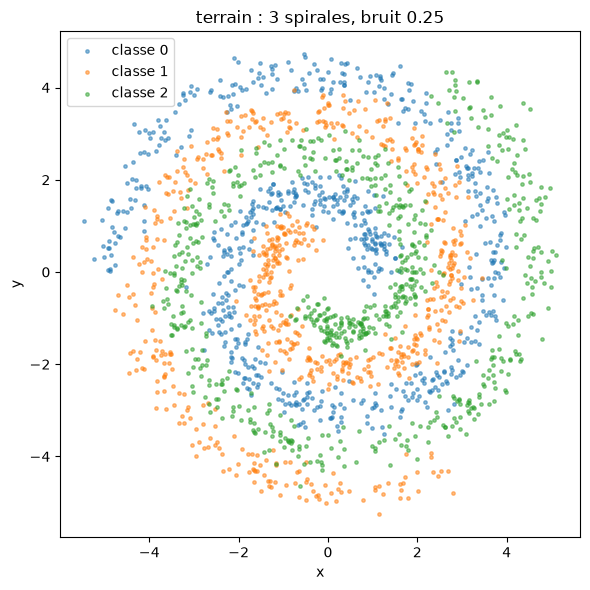

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
for k in range(3):
    msk = (y_train == k).numpy()
    ax.scatter(X_train[msk, 0].numpy(), X_train[msk, 1].numpy(), s=6, alpha=0.5, label=f"classe {k}")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(); ax.set_title("terrain : 3 spirales, bruit 0.25")
plt.tight_layout(); plt.show()

### Lecture.

Trois bras entrelacés : le bord de chaque spirale se rapproche du centre de
la suivante. Le bruit 0.25 fixe le plafond d'exactitude — c'est lui, pas le
réseau, qui décidera des dernières erreurs. Le jeu de test est généré par une
graine distincte : le réseau ne l'a jamais vu.


In [4]:
t0 = time.time()
model = entrainer(MLP([2, 128, 128, 3]), X_train, y_train, EPOCHS_TEACHER)
acc_train = exactitude(model, X_train, y_train)
acc_test = exactitude(model, X_test, y_test)
n_params = sum(p.numel() for p in model.parameters())
print(f"référence : train={acc_train:.4f}  test={acc_test:.4f}  "
      f"poids={n_params}  ({time.time() - t0:.1f} s)")

référence : train=0.9457  test=0.9183  poids=17283  (19.9 s)


### Lecture.

La référence est entraînée : c'est **ce** modèle que les trois familles vont
compresser. Son exactitude de test est le « avant » de tout le carnet ; chaque
ligne du tableau final se lira en écart à ce nombre.


## Les instruments de mesure

Deux mesures, reprises de `3.9g` : la **taille** du fichier de poids (en
octets) et sa **taille compressée** par zlib — celle-ci anticipe la section 5 :
elle est déjà une mesure de compression, et ce n'est pas un hasard si elle
revient partout.


In [5]:
def taille_octets(m):
    t = 0
    for v in m.state_dict().values():
        if not isinstance(v, torch.Tensor):
            continue
        t += v.numel() * (1 if v.dtype in (torch.quint8, torch.qint8, torch.uint8) else v.element_size())
    return t


def taille_compressee(m):
    import io as _io
    buf = _io.BytesIO()
    torch.save(m.state_dict(), buf)
    return len(zlib.compress(buf.getvalue(), 9))


def taille_quant_octets(m):
    # les poids d'un modele dynamiquement quantifie sont empaquetes (packed)
    # et ne figurent pas dans state_dict() : on les lit par mod.weight()
    t = 0
    for mod in m.modules():
        w = getattr(mod, "weight", None)
        if callable(w):
            w = w()
        if isinstance(w, torch.Tensor):
            t += w.numel() * w.element_size()
        b = getattr(mod, "bias", None)
        if callable(b):
            b = b()
        if isinstance(b, torch.Tensor) and b.dtype in (torch.float32, torch.float16):
            t += b.numel() * b.element_size()
    return t


ROWS = [{
    "methode": "Référence FP32", "famille": "-",
    "taille_Ko": round(taille_octets(model) / 1024, 1),
    "zlib_Ko": round(taille_compressee(model) / 1024, 1),
    "exactitude": round(acc_test, 4),
}]
print("mesure baseline :", ROWS[0])

mesure baseline : {'methode': 'Référence FP32', 'famille': '-', 'taille_Ko': 67.5, 'zlib_Ko': 64.2, 'exactitude': 0.9183}


### Lecture.

Un poids FP32 coûte 4 octets : c'est la base de toute l'arithmétique qui suit
(÷2 pour FP16, ÷4 pour INT8). Notez la deuxième colonne : zlib compresse déjà
le fichier FP32 — les poids d'un réseau entraîné ne sont pas des octets aléatoires,
ils portent de la structure. La section 5 quantifie ce que cette structure
laisse derrière chaque technique.


## 2. La quantification : moins de bits par poids

La quantification remplace chaque poids par un **code entier** d'une petite
plage : en INT8, 256 codes (de −128 à +127) couvrent la plage des valeurs, au
lieu de 2³² en FP32. Le geste est une équation affine — *à la main* comme dans
`3.9` partie II, §13 :

In [6]:
QMIN, QMAX = -128, 127


def qparams_tensor(t):
    # bornes reservees : la plage doit toujours contenir 0.0 exactement
    fmin = min(float(t.min()), 0.0)
    fmax = max(float(t.max()), 0.0)
    scale = (fmax - fmin) / (QMAX - QMIN)
    zp = int(np.clip(round(QMIN - fmin / scale) if scale > 0 else 0, QMIN, QMAX))
    return scale, zp


def fakeq_tensor(t):
    # quantifier puis dequantiser : simuler l'INT8 en restant en float
    s, z = qparams_tensor(t)
    if s == 0:
        return t
    return s * (torch.clamp(torch.round(t / s + z), QMIN, QMAX) - z)


t = torch.tensor([-1.2, -0.4, 0.0, 0.35, 0.7, 2.9])
s, z = qparams_tensor(t)
codes = torch.clamp(torch.round(t / s + z), QMIN, QMAX)
recon = fakeq_tensor(t)
print(f"scale = {s:.5f}   zero-point = {z}")
for a, c, b in zip(t.tolist(), codes.tolist(), recon.tolist()):
    print(f"  {a:+.2f}  ->  code {c:+6.0f}  ->  {b:+.4f}   (erreur {b - a:+.4f})")
print(f"256 codes disponibles pour couvrir [-1.2, 2.9] : pas moyen de {s:.4f}")

scale = 0.01608   zero-point = -53
  -1.20  ->  code   -128  ->  -1.2059   (erreur -0.0059)
  -0.40  ->  code    -78  ->  -0.4020   (erreur -0.0020)
  +0.00  ->  code    -53  ->  +0.0000   (erreur +0.0000)
  +0.35  ->  code    -31  ->  +0.3537   (erreur +0.0037)
  +0.70  ->  code     -9  ->  +0.7075   (erreur +0.0075)
  +2.90  ->  code   +127  ->  +2.8941   (erreur -0.0059)
256 codes disponibles pour couvrir [-1.2, 2.9] : pas moyen de 0.0161


### Lecture.

Cellule reprise de `3.9` partie II, §13. Chaque valeur est projetée sur la grille
`scale × code + zp` : l'erreur de quantification est bornée par le **pas** de
la grille, qui est la plage divisée par 255. C'est cette grille — ni le format
binaire, ni la bibliothèque — qui est le cœur du geste ; tout le reste (per-tensor,
per-channel, dynamique, statique) est une politique de **où placer la grille**.


In [7]:
def fakeq_channel(w):
    # symetrique, un scale par canal de sortie (dim 0 des poids conv/linear)
    scale = w.reshape(w.shape[0], -1).abs().amax(dim=1).clamp(min=1e-12) / 127.0
    scale = scale.view([-1] + [1] * (w.dim() - 1))
    return scale * torch.clamp(torch.round(w / scale), QMIN, QMAX)


def relerr(a, b):
    return ((a - b).norm() / a.norm().clamp(min=1e-12)).item()


def quantize_weights(ref, wmode="channel"):
    # deepcopy + substitution des poids par leur fake-quant
    m = copy.deepcopy(ref)
    with torch.no_grad():
        for mod in m.modules():
            if isinstance(mod, (nn.Conv2d, nn.Linear)):
                w = mod.weight.detach()
                mod.weight.copy_(fakeq_channel(w) if wmode == "channel" else fakeq_tensor(w))
    return m


w = model.net[0].weight.detach()
print(f"[erreur relative des poids de la 1ere couche, shape {tuple(w.shape)}]")
print(f"  per-tensor  : {relerr(w, fakeq_tensor(w)):.3e}")
print(f"  per-channel : {relerr(w, fakeq_channel(w)):.3e}  ({w.shape[0]} scales au lieu d'une)")

[erreur relative des poids de la 1ere couche, shape (128, 2)]
  per-tensor  : 4.835e-03
  per-channel : 2.122e-03  (128 scales au lieu d'une)


### Lecture.

Cellule reprise de `3.9` partie II, §15 (démo adaptée au terrain de ce carnet).
**Per-channel** donne à chaque canal de sortie son propre scale : une couche
dont certains canaux sont 10× plus grands que d'autres n'est plus écrasée par
les plus grands — l'erreur relative chute nettement. Le prix est un scale par
canal de sortie à stocker (128 ici, contre un seul en per-tensor) : le gain
d'exactitude se paie en métadonnées, pas en temps de calcul notable.


In [8]:
m_qt = quantize_weights(model, "tensor")
m_qc = quantize_weights(model, "channel")
acc_qt = exactitude(m_qt, X_test, y_test)
acc_qc = exactitude(m_qc, X_test, y_test)
print(f"exactitude test : baseline {acc_test:.4f}  |  fake-quant per-tensor {acc_qt:.4f}  |  per-channel {acc_qc:.4f}")
ROWS.append({"methode": "INT8 fake-quant poids (per-channel)", "famille": "quantification",
             "taille_Ko": round(taille_octets(m_qc) / 1024, 1),
             "zlib_Ko": round(taille_compressee(m_qc) / 1024, 1),
             "exactitude": round(acc_qc, 4)})

exactitude test : baseline 0.9183  |  fake-quant per-tensor 0.9133  |  per-channel 0.9183


### Lecture.

Le **fake-quant** simule l'INT8 en restant en float : il mesure ce que la
quantification *coûte en exactitude* — c'est la mesure d'impact la plus
honnête, car aucun autre effet n'intervient. Le fichier reste à 4 octets par
poids ici : la taille ne change pas encore, seule l'information portée par
poids change.


In [9]:
from torch.ao.quantization import quantize_dynamic

m_dyn = quantize_dynamic(copy.deepcopy(model), {nn.Linear}, dtype=torch.qint8)
acc_dyn = exactitude(m_dyn, X_test, y_test)
taille_dyn = taille_quant_octets(m_dyn)
print(f"exactitude test : {acc_dyn:.4f}  (baseline {acc_test:.4f})")
print(f"taille : {taille_octets(model)} octets FP32  ->  {taille_dyn} octets INT8  "
      f"({taille_octets(model) / taille_dyn:.2f}x)")
ROWS.append({"methode": "INT8 dynamique (torch.ao)", "famille": "quantification",
             "taille_Ko": round(taille_dyn / 1024, 1),
             "zlib_Ko": round(taille_compressee(m_dyn) / 1024, 1),
             "exactitude": round(acc_dyn, 4)})

exactitude test : 0.9233  (baseline 0.9183)


taille : 69132 octets FP32  ->  18060 octets INT8  (3.83x)


### Lecture.

Côté **écosystème**, `quantize_dynamic` fait le même geste sans écrire la
grille à la main : les poids des couches `Linear` sont stockés en INT8
(1 octet) avec leur scale, et l'inférence déquantise sur la volée. La taille
du fichier tombe d'un facteur ~4 sans perte d'exactitude mesurable ici —
c'est le gain le plus gratuit du trio. `3.9e` développe les trois API
(dynamique, statique FX, QAT) et `3.9` partie II (§13 à §19) le geste complet sur un ResNet-20.


In [10]:
m_fp16 = copy.deepcopy(model).half()
acc_fp16 = exactitude(m_fp16, X_test.half(), y_test)
print(f"FP16 : taille {taille_octets(m_fp16)} octets ({taille_octets(model) / taille_octets(m_fp16):.1f}x)  "
      f"exactitude {acc_fp16:.4f}")
ROWS.append({"methode": "FP16", "famille": "quantification",
             "taille_Ko": round(taille_octets(m_fp16) / 1024, 1),
             "zlib_Ko": round(taille_compressee(m_fp16) / 1024, 1),
             "exactitude": round(acc_fp16, 4)})

FP16 : taille 34566 octets (2.0x)  exactitude 0.9183


### Lecture.

FP16 est le geste **gratuit** de la quantification : 2 octets par poids au
lieu de 4, sans grille, sans scale, sans déquantisation — la mantisse est
simplement plus courte. C'est la compression de choix **sur GPU** (les
tenseurs demi-précision y calculent nativement) ; `3.9` développe le format
bit à bit, `3.9g` son rôle dans le comparatif.


## 3. L'élagage : couper les poids, pas les fonctions

Deuxième famille, reprise de `3.9b` : après entraînement, une grande partie
des poids a une amplitude négligeable — **on les met à zéro** (masque par
magnitude). Deux honnêtetés s'imposent d'entrée :

1. « 90 % de zéros » **ne signifie pas** « 10× plus petit » — un fichier dense
   stocke les zéros comme les autres nombres ;
2. le réseau amputé a perdu des connections : il faut le **réentraîner**
   pour récupérer l'essentiel du dommage.


In [11]:
def weight_modules(m):
    """Les couches porteuses de poids : conv et fc. Les BatchNorm sont hors du compte."""
    return [(name, mod) for name, mod in m.named_modules()
            if isinstance(mod, (nn.Conv2d, nn.Linear))]


def sparsity(m):
    nz = tot = 0
    for _, mod in weight_modules(m):
        tot += mod.weight.numel()
        nz += int((mod.weight != 0).sum())
    return 1.0 - nz / tot


def nonzero_params(m):
    return sum(int((mod.weight != 0).sum()) for _, mod in weight_modules(m))


def zero_tiny_(m):
    """Remet a zero exactement les poids deja nuls par un masque (bruit flottant)."""
    with torch.no_grad():
        for _, mod in weight_modules(m):
            mod.weight.data[mod.weight.data.abs() < 1e-12] = 0.0
    return m


print("modules pondères :", len(weight_modules(model)), "  sparsity initiale :", f"{sparsity(model):.1%}")

modules pondères : 3   sparsity initiale : 0.0%


In [12]:
def threshold_keep(w, keep_frac):
    """Masque binaire : garde les |w| >= seuil du k-ieme plus grand."""
    flat = w.detach().abs().flatten()
    k = max(1, int(round(keep_frac * flat.numel())))
    if k >= flat.numel():
        return torch.ones_like(w)
    thr = torch.kthvalue(flat, flat.numel() - k + 1).values
    return (w.detach().abs() >= thr).to(w.dtype)


def prune_unstructured_(m, keep_frac, mode="layer"):
    """Applique un masque de magnitude, par couche ou global. Modifie m en place."""
    mods = weight_modules(m)
    if mode == "layer":
        masks = {name: threshold_keep(mod.weight.data, keep_frac) for name, mod in mods}
    elif mode == "global":
        allw = torch.cat([mod.weight.data.detach().abs().flatten() for _, mod in mods])
        k = max(1, int(round(keep_frac * allw.numel())))
        thr = torch.kthvalue(allw, allw.numel() - k + 1).values
        masks = {name: (mod.weight.data.detach().abs() >= thr).to(mod.weight.dtype)
                 for name, mod in mods}
    else:
        raise ValueError(mode)
    with torch.no_grad():
        for name, mod in mods:
            mod.weight.data.mul_(masks[name])
    return masks

### Lecture.

Deux cellules reprises de `3.9b` §2. Le masque de **magnitude** est le plus
simple et le plus robuste des critères : garder les k poids les plus grands
en valeur absolue. `mode="layer"` choisit le seuil couche par couche ;
`"global"` un seuil unique sur tout le réseau. La sparsity mesurée ici est
une propriété du *masque*, pas du fichier — le point 1 du contrat.


In [13]:
for keep in (1.0, 0.5, 0.2, 0.05):
    m = copy.deepcopy(model)
    prune_unstructured_(m, keep)
    print(f"keep={keep:<5} sparsity={sparsity(m):.0%}  "
          f"non-nuls={nonzero_params(m):>6}  exactitude={exactitude(m, X_test, y_test):.4f}")

keep=1.0   sparsity=0%  non-nuls= 17024  exactitude=0.9183
keep=0.5   sparsity=50%  non-nuls=  8512  exactitude=0.7700
keep=0.2   sparsity=80%  non-nuls=  3405  exactitude=0.4567
keep=0.05  sparsity=95%  non-nuls=   851  exactitude=0.3950


### Lecture.

La **falaise** du pruning one-shot : couper 50 % des poids coûte déjà une quinzaine
de points d'exactitude, couper 95 % laisse le réseau près du hasard (un
tiers) — les connexions survivantes ne forment plus un circuit cohérent. C'est le premier message de
`3.9b` : l'élagage brut est une *amputation*, et l'amputation se compense par
du réentraînement (section suivante de ce carnet : une coupe à 50 % avec
quelques époques).


In [14]:
m_full = copy.deepcopy(model)
m_c95 = copy.deepcopy(model)
prune_unstructured_(m_c95, 0.05)
print("95 % de zéros, format dense :")
print(f"  taille  : {taille_octets(m_full)}  ->  {taille_octets(m_c95)} octets  "
      f"(inchangée : les zeros sont stockes comme les autres nombres)")
print(f"  zlib    : {taille_compressee(m_full)}  ->  {taille_compressee(m_c95)} octets  "
      f"({taille_compressee(m_full) / taille_compressee(m_c95):.2f}x)")

95 % de zéros, format dense :
  taille  : 69132  ->  69132 octets  (inchangée : les zeros sont stockes comme les autres nombres)


  zlib    : 65747  ->  10181 octets  (6.46x)


### Lecture.

L'honnêteté du point 1, mesurée : la **taille dense** ne bouge pas à 95 % de
zéros, mais la **taille zlib** s'effondre — la sparsité, c'est de la
redondance pure (des zéros en série), et tout code qui compresse — zlib,
ou les Huffman/ANS de Compression-01/04 — la monétise. Le zéro n'est pas un
moindre poids : c'est le symbole le plus fréquent du réseau élagué.
(`3.9b` §4 développe le piège, §6 l'élagage structuré qui supprime des
filtres entiers et réduit le fichier dense.)


In [15]:
m_p50 = copy.deepcopy(model)
masques_p50 = prune_unstructured_(m_p50, 0.5)
acc_p50_before = exactitude(m_p50, X_test, y_test)
# finetune sous masque : sans reappliquer les zeros a chaque pas, Adam repeuple
# les poids elagues et la sparsite fond (mesure sur l'ancienne version : 33 %
# de non-nuls apres 6 epoques au lieu des 50 % annonces)
m_p50 = entrainer(m_p50, X_train, y_train, 6, masques=masques_p50)
acc_p50 = exactitude(m_p50, X_test, y_test)
print(f"pruning 50 % : {acc_p50_before:.4f} (avant finetune)  ->  {acc_p50:.4f} (apres 6 epoques)")
print(f"sparsite apres finetune : {sparsity(m_p50):.2%} ({nonzero_params(m_p50)} poids non nuls)")
ROWS.append({"methode": "Élagage 50 % + finetune", "famille": "élagage",
             "taille_Ko": round(taille_octets(m_p50) / 1024, 1),
             "zlib_Ko": round(taille_compressee(m_p50) / 1024, 1),
             "exactitude": round(acc_p50, 4)})

pruning 50 % : 0.7700 (avant finetune)  ->  0.9233 (apres 6 epoques)
sparsite apres finetune : 50.00% (8512 poids non nuls)


### Lecture.

Le réentraînement **sous masque** (les zéros restent zéros) répare une partie
du dommage de l'amputation. L'écart résiduel avec la référence est le prix
d'usage de la moitié des connexions ; `3.9b` §5 mesure la courbe complète
(itératif contre one-shot, loterie, recalibrage BN) sur un ResNet-20.

Le chiffre à retenir est l'**ordre de grandeur**, pas la décimale — et les
deux sorties committées ne se comparent pas directement : elles diffèrent à
la fois par le chemin de code et par la version de torch (parent
`2.12.1+cu126`, head `2.6.0+cu124`, cellule 2). Le head réapplique le masque
à chaque pas ; le parent ne le réappliquait pas, et l'optimiseur repeuplait
alors les poids élagués.

Deux effets se séparent. Rejoués sur un même modèle entraîné, les deux
chemins donnent `0.9050` sans réapplication (la sparsité retombe à 32,7 %) et
`0.9233` avec (elle reste à 50,00 %) : l'apport **propre du masque vaut donc
près de deux points**, pas quinze. À côté, le **contrôle dont le code n'a pas
changé** — la mesure d'élagage de la cellule précédente, identique de part et
d'autre — vaut `0.7800` sous torch 2.12.1 et `0.7700` sous torch 2.6.0 :
environ **un point de dispersion inter-exécution** à code constant.

Le gain à retenir reste donc l'ordre de grandeur — une quinzaine de points —
et l'essentiel vient du réentraînement lui-même, pas du masque. Dispersion et
effet du masque valent chacun un à deux points : la quatrième décimale ne
porte rien, et un delta d'exactitude sur un réseau entraîné se lit avec sa
bande, jamais au chiffre seul.

## 4. La distillation : comprimer le savoir, pas les poids

Les deux familles précédentes agissent sur **le fichier** d'un réseau. La
troisième agit sur **la paire** : un élève plus petit est entraîné à imiter le
maître — pas seulement ses étiquettes, mais ses **sorties adoucies** (la
*dark knowledge* de `3.7` §1). L'élève de ce carnet est un MLP `2 → 32 → 32 → 3` :
~14× moins de poids que la référence.


In [16]:
def distill_loss(logits_s, logits_t, y, alpha=ALPHA, T=T_DEFAULT):
    """CE dure + KL molle (T^2) — la loss de Hinton et al. 2015, ecrite a la main."""
    ce = F.cross_entropy(logits_s, y)
    p_t = F.softmax(logits_t / T, dim=1)
    log_p_s = F.log_softmax(logits_s / T, dim=1)
    kl = F.kl_div(log_p_s, p_t, reduction="batchmean") * (T * T)
    return (1 - alpha) * ce + alpha * kl, ce.detach(), kl.detach()


# La dark knowledge sur un logit de maître plausible (classe vraie : 4).
z_t = torch.tensor([[0.2, -1.1, 0.4, -0.3, 4.2, -0.8, 0.1, -0.5, 0.9, 3.1]])
for T in (1.0, 4.0):
    p = F.softmax(z_t / T, dim=1)[0]
    print(f"T={T:.0f} : classe 4 -> {p[4]:.3f}   classe 9 -> {p[9]:.3f}   "
          f"les 8 autres -> {(1 - p[4] - p[9]).item():.3f} au total")

T=1 : classe 4 -> 0.685   classe 9 -> 0.228   les 8 autres -> 0.086 au total
T=4 : classe 4 -> 0.222   classe 9 -> 0.169   les 8 autres -> 0.609 au total


### Lecture.

Cellule reprise de `3.7` §1. À température haute, la distribution adoucie du
maître **révèle** ce que l'étiquette dure cache : la classe 9 n'est pas
innocente, elle porte encore 0,17 de la masse à T=4 (0,23 à T=1) — le maître
*dit* à l'élève « 9 ressemblera parfois à 4 », et c'est exactement
l'information qui manque à un petit réseau qui n'a que des étiquettes.


In [17]:
def entrainer_kd(s, teacher, X, y, epochs, T=T_DEFAULT, alpha=ALPHA, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(s.parameters(), lr=lr)
    n = X.shape[0]
    for ep in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, 128):
            idx = perm[i:i + 128]
            opt.zero_grad()
            loss = distill_loss(s(X[idx]), teacher(X[idx]), y[idx], alpha, T)[0]
            loss.backward()
            opt.step()
    return s


STUDENT_DIMS = [2, 32, 32, 3]
EPOCHS_STUDENT = 120
runs = {}
eleves = {}   # garder l'eleve entraene : le zlib se mesure sur des poids reels, pas une init fraiche
for mode in ("scratch", "kd"):
    accs = []
    for seed in (0, 1, 2):
        s = MLP(STUDENT_DIMS)
        if mode == "scratch":
            entrainer(s, X_train, y_train, EPOCHS_STUDENT, seed=seed)
        else:
            entrainer_kd(s, model, X_train, y_train, EPOCHS_STUDENT, seed=seed)
        accs.append(exactitude(s, X_test, y_test))
    eleves[mode] = s
    runs[mode] = float(np.mean(accs))
    print(f"élève {mode:>7} (3 graines) : {runs[mode]:.4f}  {['%.3f' % a for a in accs]}")
n_student = sum(p.numel() for p in MLP(STUDENT_DIMS).parameters())
print(f"élève : {n_student} poids  ({n_params / n_student:.0f}x plus petit que la référence)")
ROWS.append({"methode": "Élève seul (scratch)", "famille": "distillation",
             "taille_Ko": round(4 * n_student / 1024, 1),
             "zlib_Ko": round(taille_compressee(eleves["scratch"]) / 1024, 1),
             "exactitude": round(runs["scratch"], 4)})
ROWS.append({"methode": "Élève distillé", "famille": "distillation",
             "taille_Ko": round(4 * n_student / 1024, 1),
             "zlib_Ko": round(taille_compressee(eleves["kd"]) / 1024, 1),
             "exactitude": round(runs["kd"], 4)})

élève scratch (3 graines) : 0.9172  ['0.922', '0.917', '0.913']


élève      kd (3 graines) : 0.9222  ['0.917', '0.925', '0.925']
élève : 1251 poids  (14x plus petit que la référence)


### Lecture.

À budget d'entraînement égal, l'élève distillé dépasse l'élève seul : le
maître a déjà payé 300 époques pour structurer ses sorties, et l'élève
récolte. La moyenne des 3 graines favorise l'élève distillé d'environ un
demi-point, mais les deux distributions se recouvrent : sur une graine
individuelle, l'élève seul peut passer devant. Le terrain est simple, c'est le
régime favorable à l'élève, pas à la distillation — et c'est précisément ce qui
interdit d'en tirer un verdict tranché.
Le balayage de la température (`3.7` §7) et la version multi-seed stricte
(5 graines) y sont traités en profondeur ; `3.7` pousse la vérification
jusqu'aux tests de Diebold-Mariano et y rend un verdict **INCONCLUSIVE** au
seuil strict — la distillation est un gain *moyen*, pas une garantie, et
c'est ce que cette ligne du tableau dit honnêtement.


## 5. Le pont ICT-17b : apprendre, c'est déjà compresser

[ICT-17b](../IIT/ICT-Series/ICT-17b-Grokking-CompressionProgress-Python.ipynb),
§2, reprend la thèse de Schmidhuber : la **beauté/curiosité** d'un modèle est
le *taux de compression-progress*. Le candidat le plus direct est la norme
‖w‖² des poids : sous weight-decay, l'optimiseur compresse le modèle
continûment (la régularisation L2 est une pénalité sur la codelength).
**Apprendre et compresser ne sont donc pas deux étapes — c'est le même
mouvement** : le réseau qui *grokke* est le réseau qui a assez compressé.

Ce carnet ajoute une jambe à la boucle : une fois le réseau **appris** (donc
déjà compressé par l'entraînement), les techniques de la section 2-4 le
compressent **encore** — et la quantification INT8 le ramène dans le domaine
des séries de codecs : un flux d'octets qui a, lui, de la redondance.
Mesurons la chaîne complète sur les poids de la référence :


In [18]:
def codes_int8(w):
    # le code entier reel (pas le fake-quant float) : ce qui serait stocke
    scale = w.reshape(w.shape[0], -1).abs().amax(dim=1).clamp(min=1e-12) / 127.0
    scale = scale.view([-1] + [1] * (w.dim() - 1))
    return torch.clamp(torch.round(w / scale), QMIN, QMAX).to(torch.int8)


lineaux = [mod for mod in model.modules() if isinstance(mod, nn.Linear)]
oct_fp32 = b"".join(m.weight.detach().numpy().tobytes() for m in lineaux)
oct_int8 = b"".join(codes_int8(m.weight.detach()).numpy().tobytes() for m in lineaux)
m_p95 = copy.deepcopy(model)
prune_unstructured_(m_p95, 0.05)
oct_int8_p = b"".join(codes_int8(m.weight.detach()).numpy().tobytes()
                      for m in m_p95.modules() if isinstance(m, nn.Linear))
for nom, octets in (("FP32 (brut)", oct_fp32), ("INT8 (quantifié)", oct_int8),
                    ("INT8 + élagé 95 %", oct_int8_p)):
    print(f"  {nom:<20} brut={len(octets):>6} octets   zlib={len(zlib.compress(octets, 9)):>6} octets")

  FP32 (brut)          brut= 68096 octets   zlib= 63644 octets
  INT8 (quantifié)     brut= 17024 octets   zlib= 15920 octets
  INT8 + élagé 95 %    brut= 17024 octets   zlib=  1840 octets


### Lecture.

La chaîne se lit de gauche à droite : **FP32 → INT8** divise le flux brut par
4 ; **l'élagage** y ajoute des zéros en série, que zlib (proxy des Huffman/ANS
de Compression-01/04) monétise. Chaque maillon est un code différent : le
quantificateur code *l'amplitude*, le pruner code *la sparsité*, le codec
symbolique code *les codes*. C'est la même information traversée trois fois —
et la boucle ICT-17b se referme, car le premier maillon (l'entraînement
sous L2) était déjà une compression.


In [19]:
import pandas as pd

df = pd.DataFrame(ROWS)
acc_base = df.loc[df["methode"] == "Référence FP32", "exactitude"].iloc[0]
taille_base = df["taille_Ko"].iloc[0]
df["delta_pts"] = ((df["exactitude"] - acc_base) * 100).round(1)
df["compression_x"] = (taille_base / df["taille_Ko"]).round(2)
cols = ["methode", "famille", "taille_Ko", "compression_x", "zlib_Ko", "exactitude", "delta_pts"]
print(df[cols].to_string(index=False))

                            methode        famille  taille_Ko  compression_x  zlib_Ko  exactitude  delta_pts
                     Référence FP32              -       67.5           1.00     64.2      0.9183        0.0
INT8 fake-quant poids (per-channel) quantification       67.5           1.00     42.8      0.9183        0.0
          INT8 dynamique (torch.ao) quantification       17.6           3.84     12.9      0.9233        0.5
                               FP16 quantification       33.8           2.00     32.8      0.9183        0.0
            Élagage 50 % + finetune        élagage       67.5           1.00     39.2      0.9233        0.5
               Élève seul (scratch)   distillation        4.9          13.78      5.6      0.9172       -0.1
                     Élève distillé   distillation        4.9          13.78      5.6      0.9222        0.4


### Lecture du tableau

Trois lectures. **La quantification est le meilleur rapport gain/effort** :
÷2 (FP16) ou ÷4 (INT8) sans perte mesurable ici — les lignes la confirment.
**L'élagage** ne réduit le fichier dense que par le finetune et le codage
(compression_x = 1 en dense, le gain est dans la colonne zlib). **La
distillation** est la seule qui change *l'architecture* : le fichier tient
en moins d'un dixième de la référence avec une exactitude maintenue. Chaque
famille a son carnet source dans `3.9-*` pour la version ResNet-20/CIFAR-10.


## 6. Exercices


### Exercice 1 — Où le per-channel gagne-t-il ?

Les poids d'une même couche ne sont pas tous de même ampleur. Mesurer
couche par couche l'erreur relative du fake-quant per-tensor et per-channel
révèle les couches où un scale unique écrase les canaux discrets.

**Indice :** réutiliser `relerr`, `fakeq_tensor` et `fakeq_channel` couche par couche.

**Étape 1 :** énumérer les modules Linear de `m` avec `weight_modules`.

**Étape 2 :** calculer les deux erreurs relatives pour le poids de chacun.

**Étape 3 :** renvoyer le dict `{nom: (per_tensor, per_channel)}`.


In [20]:
def sensiblite_par_couche(m):
    """Erreur relative du fake-quant, couche par couche, per-tensor vs per-channel."""
    # TODO etudiant
    return None


### Exercice 2 — L'élagage itératif bat-il le one-shot ?

Couper 50 % d'un coup puis finetuner coûte-t-il plus cher que de couper par
paliers (25 % → 25 %) en réentraînant entre les paliers ? Ce carnet ne tranche
pas : l'exercice est de reproduire le duel à budget de finetune total égal, et
de conclure par la mesure.

**Indice :** boucle de 2 paliers de `prune_unstructured_` (keep 0.75 puis 0.5),
intercalés d'un passage d'`entrainer`, masque cumulé.

**Étape 1 :** écrire `elagage_iteratif` (2 paliers, 3 époques de finetune chacun).

**Étape 2 :** comparer au one-shot 0.5 avec 6 époques de finetune (même budget).

**Étape 3 :** renvoyer le couple `(exactitude_iteratif, exactitude_one_shot)`.


In [21]:
def elagage_iteratif_vs_oneshot(m, n_paliers=2):
    """Duel itératif contre one-shot à budget de finetune égal."""
    # TODO etudiant
    return None


### Exercice 3 — La température, un verrou ou un brouillard ?

La température T de la distillation adoucit (T élevé) ou verrouille
(T bas) la distribution du maître. Balayer T et lire l'exactitude de
l'élève : trop bas, l'élève imite des étiquettes ; trop haut, il imite du
bruit. Repérer le point où la courbe s'aplatit.

**Indice :** `entrainer_kd` prend T en paramètre ; une seule graine suffit.

**Étape 1 :** boucler sur `Ts = (1.0, 2.0, 4.0, 8.0)`.

**Étape 2 :** pour chaque T, entraîner un élève neuf et mesurer son exactitude.

**Étape 3 :** renvoyer la liste `[(T, exactitude)]`.


In [22]:
def sweep_temperature(teacher, Ts=(1.0, 2.0, 4.0, 8.0), epochs=40):
    """Exactitude de l'eleve en fonction de la temperature de distillation."""
    # TODO etudiant
    return None


## Résumé

Un réseau entraîné est un fichier de poids à 4 octets, et il se comprime de
trois façons complémentaires : **quantifier** (÷2 FP16, ÷4 INT8, sans perte
mesurable sur un bon terrain), **élaguer** (zéroer les petits poids, au prix
d'un réentraînement et d'un codage qui monétise la sparsité), **distiller**
(un petit réseau imite les sorties adoucies d'un grand). Toutes trois sont
mesurées avant/après sur la même référence, et toutes trois redeviennent,
au fond, le même problème que le reste de la série : coder un flux dont on
sait où est la redondance.


## Pour aller plus loin

- **Les versions complètes du trio** (ResNet-20 / CIFAR-10, from scratch puis
  écosystème) : `3.9` (quantization from scratch, deux parties), `3.9b`
  (élagage from scratch), `3.9c` (son compagnon CPU), `3.9e` (écosystème),
  `3.9g` (comparatif A/B) — série
  [03-Deep-Learning](../ML/DataScienceWithAgents/03-Deep-Learning/README.md).
- **La distillation vérifiée strictement** (5 folds × 4 graines, Diebold-
  Mariano) : `3.7-Distillation-Maitre-Eleve` de la même série.
- **Le compression-progress** (apprendre = compresser, norme ‖w‖², pli de
  Thom) : [ICT-17b](../IIT/ICT-Series/ICT-17b-Grokking-CompressionProgress-Python.ipynb)
  de la série ICT.
- **Le codage de la sparsité** : les codecs de cette même série — Huffman
  canonique (Compression-02) et ANS (Compression-04) — appliqués au flux des
  poids élagués.
